In [5]:
import kagglehub
import matplotlib.pyplot as plt
import pandas as pd
pd.set_option("display.max.columns", None)


In [ ]:
# path = kagglehub.dataset_download("bwandowando/clash-royale-season-18-dec-0320-dataset", output_dir="./data")
# print(path)

100%|██████████| 5.03G/5.03G [04:36<00:00, 19.5MB/s]

Extracting files...


### Rough EDA procedure
1. Investigate what each column represents (e.g. what is each gamemodeId?)
2. Investigate which columns we should keep
3. Clear up null values or replace them with reasonable values

In [6]:
# first batch
df = pd.read_csv("data/BattlesStaging_01012021_WL_tagged/BattlesStaging_01012021_WL_tagged.csv")

In [7]:
df.head()

,Unnamed: 0,battleTime,arena.id,gameMode.id,average.startingTrophies,winner.tag,winner.startingTrophies,winner.trophyChange,winner.crowns,winner.kingTowerHitPoints,winner.princessTowersHitPoints,winner.clan.tag,winner.clan.badgeId,loser.tag,loser.startingTrophies,loser.trophyChange,loser.crowns,loser.kingTowerHitPoints,loser.clan.tag,loser.clan.badgeId,loser.princessTowersHitPoints,tournamentTag,winner.card1.id,winner.card1.level,winner.card2.id,winner.card2.level,winner.card3.id,winner.card3.level,winner.card4.id,winner.card4.level,winner.card5.id,winner.card5.level,winner.card6.id,winner.card6.level,winner.card7.id,winner.card7.level,winner.card8.id,winner.card8.level,winner.cards.list,winner.totalcard.level,winner.troop.count,winner.structure.count,winner.spell.count,winner.common.count,winner.rare.count,winner.epic.count,winner.legendary.count,winner.elixir.average,loser.card1.id,loser.card1.level,loser.card2.id,loser.card2.level,loser.card3.id,loser.card3.level,loser.card4.id,loser.card4.level,loser.card5.id,loser.card5.level,loser.card6.id,loser.card6.level,loser.card7.id,loser.card7.level,loser.card8.id,loser.card8.level,loser.cards.list,loser.totalcard.level,loser.troop.count,loser.structure.count,loser.spell.count,loser.common.count,loser.rare.count,loser.epic.count,loser.legendary.count,loser.elixir.average
0,0,2020-12-31 21:02:12+00:00,54000050.0,72000006.0,5363.0,#PVLPJP2Y,5372.0,28.0,2.0,4145.0,[1484],#2PYV00GQ,16000030.0,#PLYJVUQY2,5354.0,-28.0,1.0,1402.0,#8G2QJ9Y2,16000044.0,NaN,NaN,26000008,13,26000022,13,28000001,13,26000004,13,26000003,13,27000004,13,28000002,13,26000006,13,"[26000003, 26000004, 26000006, 26000008, 26000...",104,5,1,2,3,2,3,0,4.500,27000004,13,26000015,13,28000010,13,28000009,13,28000012,13,26000023,13,26000000,13,28000015,13,"[26000000, 26000015, 26000023, 27000004, 28000...",104,3,1,4,1,1,4,2,3.500
1,1,2020-12-31 21:02:15+00:00,54000050.0,72000006.0,5407.0,#8PRLRYYCV,5409.0,29.0,1.0,5304.0,"[579, 3082]",NaN,NaN,#92VG2CPY,5405.0,-29.0,0.0,5107.0,#8V22RYJ9,16000097.0,[2280],NaN,26000056,13,28000011,12,27000003,12,26000010,12,28000004,13,26000000,13,26000040,12,26000026,12,"[26000000, 26000010, 26000026, 26000040, 26000...",99,5,1,2,2,2,2,2,2.875,26000037,13,26000046,13,26000055,13,28000009,13,27000001,13,26000062,13,26000023,13,26000027,13,"[26000023, 26000027, 26000037, 26000046, 26000...",104,6,1,1,0,1,2,5,4.250
2,2,2020-12-31 21:02:45+00:00,54000050.0,72000006.0,5741.0,#2G8LQRCG,5749.0,28.0,2.0,5762.0,"[2080, 2099]",#29GY0C28,16000112.0,#2PCUY9U80,5733.0,-28.0,0.0,2070.0,#YCU29JR2,16000077.0,NaN,NaN,26000044,13,26000059,13,26000010,13,26000061,13,26000055,13,26000042,13,28000015,13,28000008,13,"[26000010, 26000042, 26000044, 26000055, 26000...",104,6,0,2,2,1,2,3,3.500,26000046,13,26000041,13,26000028,13,26000049,13,26000022,13,26000027,13,28000008,13,26000059,13,"[26000022, 26000027, 26000028, 26000041, 26000...",104,7,0,1,4,2,1,1,4.125
3,3,2020-12-31 21:03:13+00:00,54000050.0,72000006.0,4307.0,#Y9QL09VGV,4316.0,28.0,2.0,4392.0,[1322],#2J9YCYG0,16000168.0,#9GJJGYL8P,4298.0,-28.0,1.0,4228.0,#YR9YCRRC,16000163.0,NaN,NaN,28000004,11,28000000,9,26000041,11,26000016,10,26000026,10,28000011,11,26000023,10,28000012,8,"[26000016, 26000023, 26000026, 26000041, 28000...",80,4,0,4,1,1,3,3,3.250,26000027,10,26000031,10,28000000,10,26000033,10,26000046,10,26000012,10,26000062,10,27000006,10,"[26000012, 26000027, 26000031, 26000033, 26000...",80,6,1,1,2,1,2,3,3.750
4,4,2020-12-31 21:03:17+00:00,54000050.0,72000006.0,5776.5,#9RRYG9P9U,5783.0,28.0,3.0,5832.0,"[3668, 3668]",#V0U,16000054.0,#80J0LUCP8,5770.0,-28.0,0.0,NaN,#2QP222UU,16000114.0,NaN,NaN,28000011,13,26000021,13,26000014,13,26000038,13,28000000,13,26000030,13,26000010,13,27000000,13,"[26000010, 26000014, 26000021, 26000030, 26000...",104,5,1,2,3,4,0,1,2.625,26000021,13,27000004,13,26000037,13,28000011,13,26000064,13,28000000,13,26000011,13,26000010,13,"[26000010, 26000011, 26000021, 26000037, 26000...",104,5,1,2,2,4,0,2,3.250


In [8]:
metadata = ["winner.clan.tag", "winner.clan.badgeId", "winner.kingTowerHitPoints", "winner.princessTowersHitPoints", "loser.clan.tag", "loser.clan.badgeId", "loser.kingTowerHitPoints", "loser.princessTowersHitPoints", "tournamentTag"]
card_data = []
for player in ["winner", "loser"]:
    card_data.append(f"{player}.totalcard.level")
    card_data.append(f"{player}.troop.count")
    card_data.append(f"{player}.structure.count")
    card_data.append(f"{player}.spell.count")
    card_data.append(f"{player}.common.count")
    card_data.append(f"{player}.rare.count")
    card_data.append(f"{player}.epic.count")
    card_data.append(f"{player}.legendary.count")
    card_data.append(f"{player}.elixir.average")
    card_data.append(f"{player}.cards.list")
    for i in range(1,9):
        card_data.append(f"{player}.card{i}.id")
        card_data.append(f"{player}.card{i}.level")

combined_metadata = metadata + card_data
cleaned = df.drop(columns=combined_metadata)
cleaned.head()

,Unnamed: 0,battleTime,arena.id,gameMode.id,average.startingTrophies,winner.tag,winner.startingTrophies,winner.trophyChange,winner.crowns,loser.tag,loser.startingTrophies,loser.trophyChange,loser.crowns
0,0,2020-12-31 21:02:12+00:00,54000050.0,72000006.0,5363.0,#PVLPJP2Y,5372.0,28.0,2.0,#PLYJVUQY2,5354.0,-28.0,1.0
1,1,2020-12-31 21:02:15+00:00,54000050.0,72000006.0,5407.0,#8PRLRYYCV,5409.0,29.0,1.0,#92VG2CPY,5405.0,-29.0,0.0
2,2,2020-12-31 21:02:45+00:00,54000050.0,72000006.0,5741.0,#2G8LQRCG,5749.0,28.0,2.0,#2PCUY9U80,5733.0,-28.0,0.0
3,3,2020-12-31 21:03:13+00:00,54000050.0,72000006.0,4307.0,#Y9QL09VGV,4316.0,28.0,2.0,#9GJJGYL8P,4298.0,-28.0,1.0
4,4,2020-12-31 21:03:17+00:00,54000050.0,72000006.0,5776.5,#9RRYG9P9U,5783.0,28.0,3.0,#80J0LUCP8,5770.0,-28.0,0.0


In [9]:
cleaned.describe()

,Unnamed: 0,arena.id,gameMode.id,average.startingTrophies,winner.startingTrophies,winner.trophyChange,winner.crowns,loser.startingTrophies,loser.trophyChange,loser.crowns
count,2.823527e+06,2.823527e+06,2.823527e+06,2.823527e+06,2.823527e+06,2.823527e+06,2.823527e+06,2.823527e+06,2.823527e+06,2.823527e+06
mean,1.411763e+06,5.400005e+07,7.200013e+07,4.768460e+03,4.768758e+03,2.948102e+01,1.795677e+00,4.768162e+03,-2.927499e+01,3.259133e-01
std,8.150822e+05,8.943203e+00,9.342613e+01,7.625911e+02,7.626247e+02,1.470124e+00,8.474047e-01,7.626487e+02,2.515316e+00,5.106455e-01
min,0.000000e+00,5.400000e+07,7.200001e+07,2.450000e+01,2.300000e+01,1.000000e+00,1.000000e+00,2.400000e+01,-5.800000e+01,0.000000e+00
25%,7.058815e+05,5.400005e+07,7.200001e+07,4.401500e+03,4.402000e+03,2.900000e+01,1.000000e+00,4.401000e+03,-3.000000e+01,0.000000e+00
50%,1.411763e+06,5.400005e+07,7.200020e+07,4.758000e+03,4.759000e+03,3.000000e+01,2.000000e+00,4.758000e+03,-3.000000e+01,0.000000e+00
75%,2.117644e+06,5.400005e+07,7.200020e+07,5.176500e+03,5.176000e+03,3.000000e+01,3.000000e+00,5.176000e+03,-2.900000e+01,1.000000e+00
max,2.823526e+06,5.400005e+07,7.200020e+07,7.439500e+03,7.486000e+03,5.800000e+01,3.000000e+00,7.482000e+03,-1.000000e+00,2.000000e+00


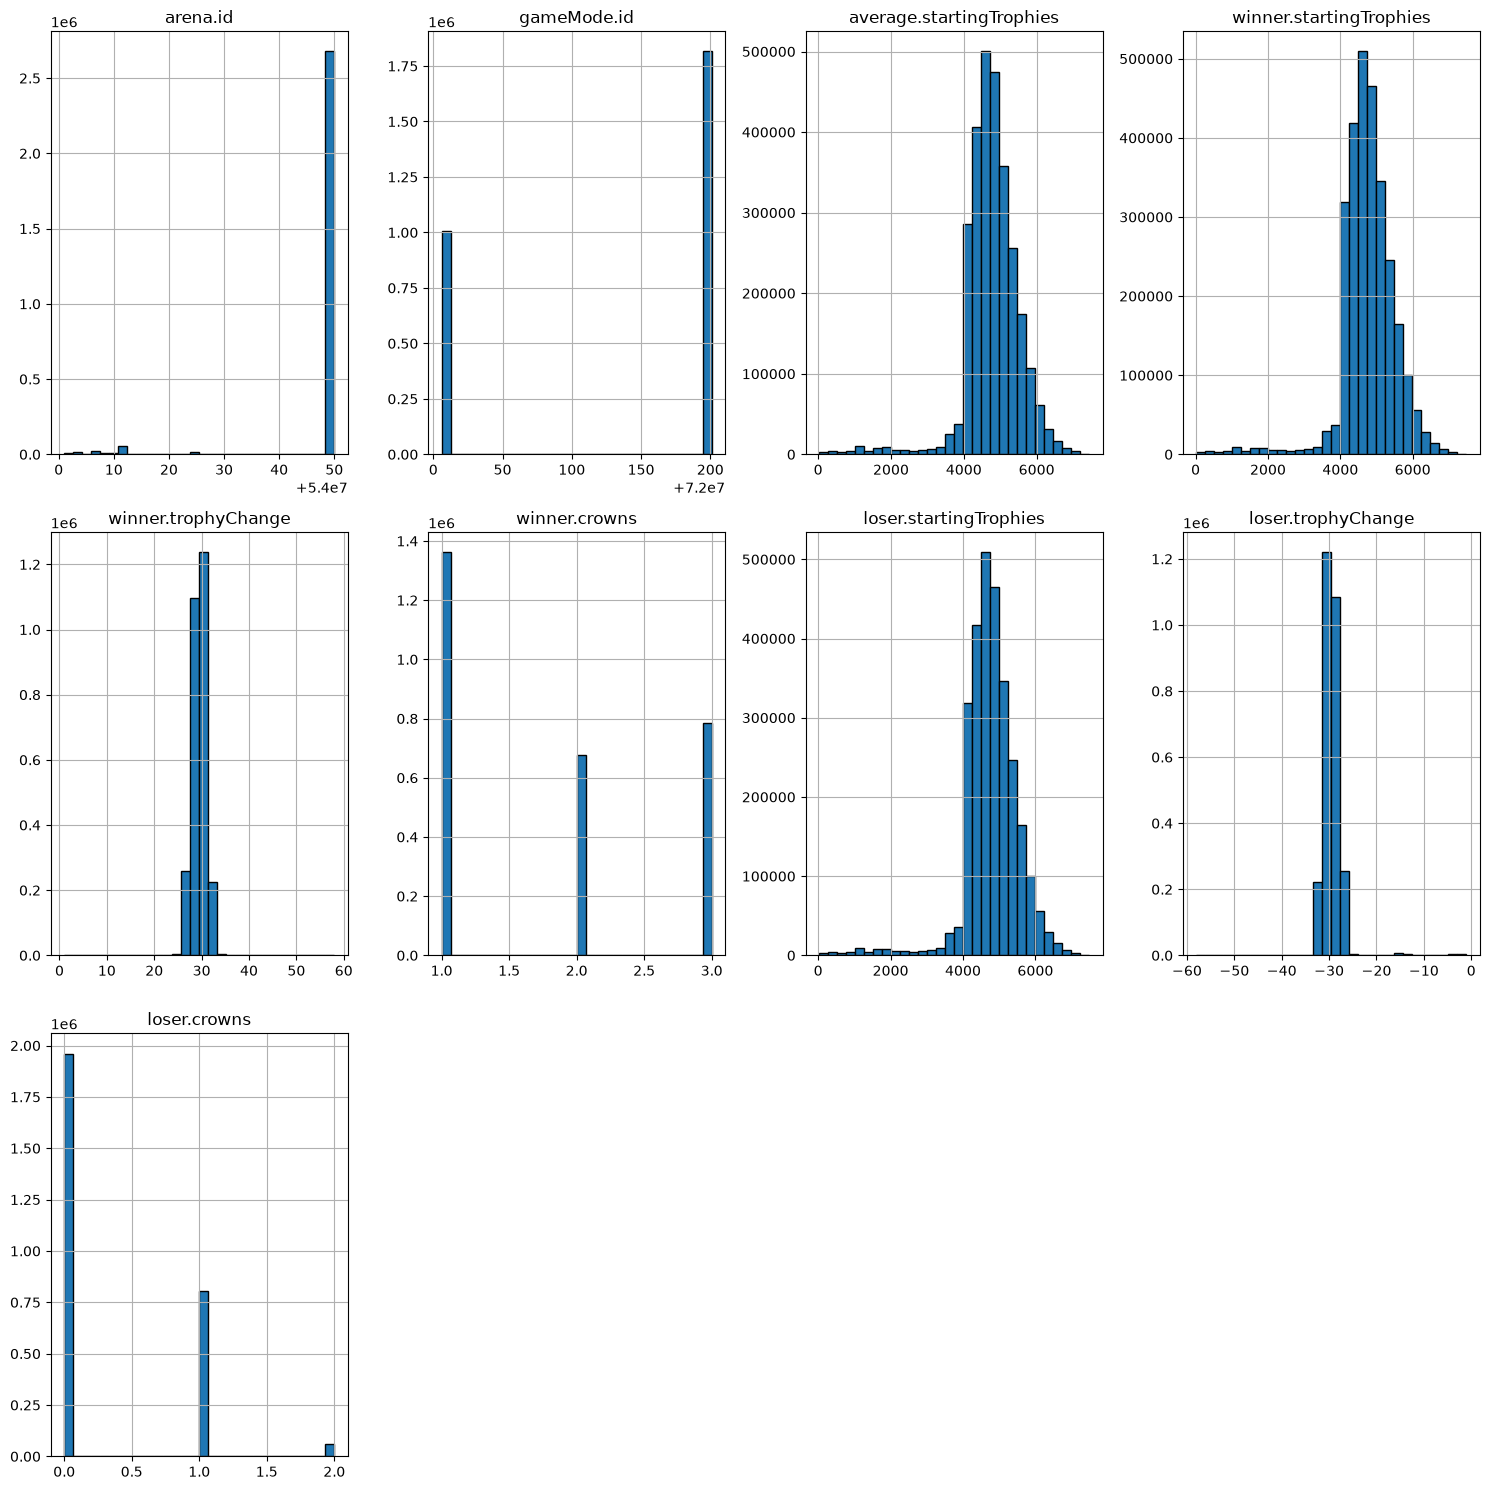

In [29]:
cleaned.drop(columns=["Unnamed: 0"]).hist(figsize=(15, 15), layout=(-1,4), bins=30, edgecolor="black")
plt.tight_layout()
plt.show()

# Reformatting the data
We now want to create a table where the rows are:
- User ID
- Start time of the match
- Trophy count before the match
- Outcome of the match

We eventually want to be able to group by User ID and sort all games by date.
Each row in the cleaned table contains a single unique game, where there is a winner and a loser.
For each row, append to the new df the User ID, start time, trophy count, and outcome.

We can vectorize this operation with `df.melt(id_vars, value_vars)`:
it is essentially just $$[(id_{vars})]\times[value_{vars}]=[(id_1+\dots+id_m)]\times[value_1+\dots+value_n]$$
$$=(id_1+\dots+id_m)(value_1)+\dots+(id_1+\dots+id_n)(value_n)$$

where multiplication of $()$ is concatenation and multiplcation of $[]$ is distributive in the usual real number sense.

In [30]:
reshaped = cleaned.melt(id_vars=["battleTime","winner.startingTrophies", "loser.startingTrophies"], value_vars=["winner.tag", "loser.tag"], var_name="outcome", value_name="user")
reshaped.head()

,battleTime,winner.startingTrophies,loser.startingTrophies,outcome,user
0,2020-12-31 21:02:12+00:00,5372.0,5354.0,winner.tag,#PVLPJP2Y
1,2020-12-31 21:02:15+00:00,5409.0,5405.0,winner.tag,#8PRLRYYCV
2,2020-12-31 21:02:45+00:00,5749.0,5733.0,winner.tag,#2G8LQRCG
3,2020-12-31 21:03:13+00:00,4316.0,4298.0,winner.tag,#Y9QL09VGV
4,2020-12-31 21:03:17+00:00,5783.0,5770.0,winner.tag,#9RRYG9P9U


In [31]:
def trophies(row):
    if row["outcome"] == "winner.tag":
        return row["winner.startingTrophies"]
    else:
        return row["loser.startingTrophies"]

reshaped["trophies"] = reshaped.apply(trophies, axis=1)
reshaped.head()

,battleTime,winner.startingTrophies,loser.startingTrophies,outcome,user,trophies
0,2020-12-31 21:02:12+00:00,5372.0,5354.0,winner.tag,#PVLPJP2Y,5372.0
1,2020-12-31 21:02:15+00:00,5409.0,5405.0,winner.tag,#8PRLRYYCV,5409.0
2,2020-12-31 21:02:45+00:00,5749.0,5733.0,winner.tag,#2G8LQRCG,5749.0
3,2020-12-31 21:03:13+00:00,4316.0,4298.0,winner.tag,#Y9QL09VGV,4316.0
4,2020-12-31 21:03:17+00:00,5783.0,5770.0,winner.tag,#9RRYG9P9U,5783.0


In [32]:
def rename_outcome(row):
    if row["outcome"] == "winner.tag":
        return "win"
    return "loss"

reshaped["outcome"] = reshaped.apply(rename_outcome, axis=1)
reshaped = reshaped.drop(columns=["winner.startingTrophies", "loser.startingTrophies"])
reshaped.head()


,battleTime,outcome,user,trophies
0,2020-12-31 21:02:12+00:00,win,#PVLPJP2Y,5372.0
1,2020-12-31 21:02:15+00:00,win,#8PRLRYYCV,5409.0
2,2020-12-31 21:02:45+00:00,win,#2G8LQRCG,5749.0
3,2020-12-31 21:03:13+00:00,win,#Y9QL09VGV,4316.0
4,2020-12-31 21:03:17+00:00,win,#9RRYG9P9U,5783.0


In [35]:
reshaped = reshaped.sort_values(by=["battleTime"])
reshaped.head(10)

,battleTime,outcome,user,trophies
1456889,2020-12-31 21:01:52+00:00,win,#9CJQ2JJ98,4505.0
4280416,2020-12-31 21:01:52+00:00,loss,#YVL9LV9Q8,4504.0
2823527,2020-12-31 21:02:12+00:00,loss,#PLYJVUQY2,5354.0
0,2020-12-31 21:02:12+00:00,win,#PVLPJP2Y,5372.0
2823528,2020-12-31 21:02:15+00:00,loss,#92VG2CPY,5405.0
1,2020-12-31 21:02:15+00:00,win,#8PRLRYYCV,5409.0
4280417,2020-12-31 21:02:37+00:00,loss,#PPLRJ888U,5245.0
1456890,2020-12-31 21:02:37+00:00,win,#2GURYLY8,5214.0
2823529,2020-12-31 21:02:45+00:00,loss,#2PCUY9U80,5733.0
2,2020-12-31 21:02:45+00:00,win,#2G8LQRCG,5749.0
